# Notebook 03: Baseline Models & Cross-Validation
Evaluates baseline machine learning models on the 819 real Zenodo trials using **5-fold `GroupKFold` cross-validation** grouped strictly by unique biological participant IDs ($N=38$) to prevent cross-participant label leakage.

**Evaluated Models:**
1. **Dummy Classifier** (Stratified chance baseline)
2. **Logistic Regression** (L2 regularized, sigmoid probability calibration)
3. **Random Forest Classifier** (100 estimators, depth 5, balanced)
4. **XGBoost Classifier** (100 estimators, depth 4, learning rate 0.05)

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, brier_score_loss, roc_curve
import xgboost as xgb
import matplotlib.pyplot as plt

df = pd.read_csv(r"E:\karthianna\data\processed\zenodo_features.csv")
feature_cols = [
    'early_probe_diff', 'mid_probe_diff', 'late_probe_diff', 'total_probe_diff',
    'mean_fix_duration', 'median_fix_duration', 'fixation_count'
]
X = df[feature_cols].fillna(0.0)
y = df['familiarity_label']
groups = df['participant_id']

print(f"Loaded {len(X)} trials across {groups.nunique()} biological participants.")

Loaded 819 trials across 38 biological participants.


In [2]:
gkf = GroupKFold(n_splits=5)
models = {
    'Dummy Classifier': DummyClassifier(strategy='stratified', random_state=42),
    'Logistic Regression': CalibratedClassifierCV(LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42), cv=3),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42, eval_metric='logloss')
}

results = {}
roc_data = {}

for name, model in models.items():
    y_true_all, y_pred_all, y_prob_all = [], [], []
    for tr_idx, val_idx in gkf.split(X, y, groups):
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X.iloc[tr_idx])
        X_val = scaler.transform(X.iloc[val_idx])
        
        model.fit(X_tr, y.iloc[tr_idx])
        preds = model.predict(X_val)
        probs = model.predict_proba(X_val)[:, 1] if hasattr(model, 'predict_proba') else preds.astype(float)
        
        y_true_all.extend(y.iloc[val_idx])
        y_pred_all.extend(preds)
        y_prob_all.extend(probs)
        
    yt = np.array(y_true_all)
    yp = np.array(y_pred_all)
    yprob = np.array(y_prob_all)
    
    bacc = balanced_accuracy_score(yt, yp)
    auc = roc_auc_score(yt, yprob)
    f1 = f1_score(yt, yp)
    brier = brier_score_loss(yt, yprob)
    cm = confusion_matrix(yt, yp)
    
    results[name] = {
        'Balanced Accuracy': f"{bacc*100:.1f}%",
        'ROC-AUC': f"{auc:.3f}",
        'F1-Score': f"{f1:.3f}",
        'Brier Loss': f"{brier:.3f}",
        'Confusion Matrix': cm.tolist()
    }
    fpr, tpr, _ = roc_curve(yt, yprob)
    roc_data[name] = (fpr, tpr, auc)

summary_df = pd.DataFrame(results).T
print("5-Fold Cross-Validation Benchmark Results (Grouped by Participant):")
print(summary_df[['Balanced Accuracy', 'ROC-AUC', 'F1-Score', 'Brier Loss']])

5-Fold Cross-Validation Benchmark Results (Grouped by Participant):
                    Balanced Accuracy ROC-AUC F1-Score Brier Loss
Dummy Classifier                48.1%   0.481    0.507      0.518
Logistic Regression             62.4%   0.677    0.667      0.225
Random Forest                   62.9%   0.682    0.672      0.225
XGBoost                         59.1%   0.652    0.613      0.242


<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


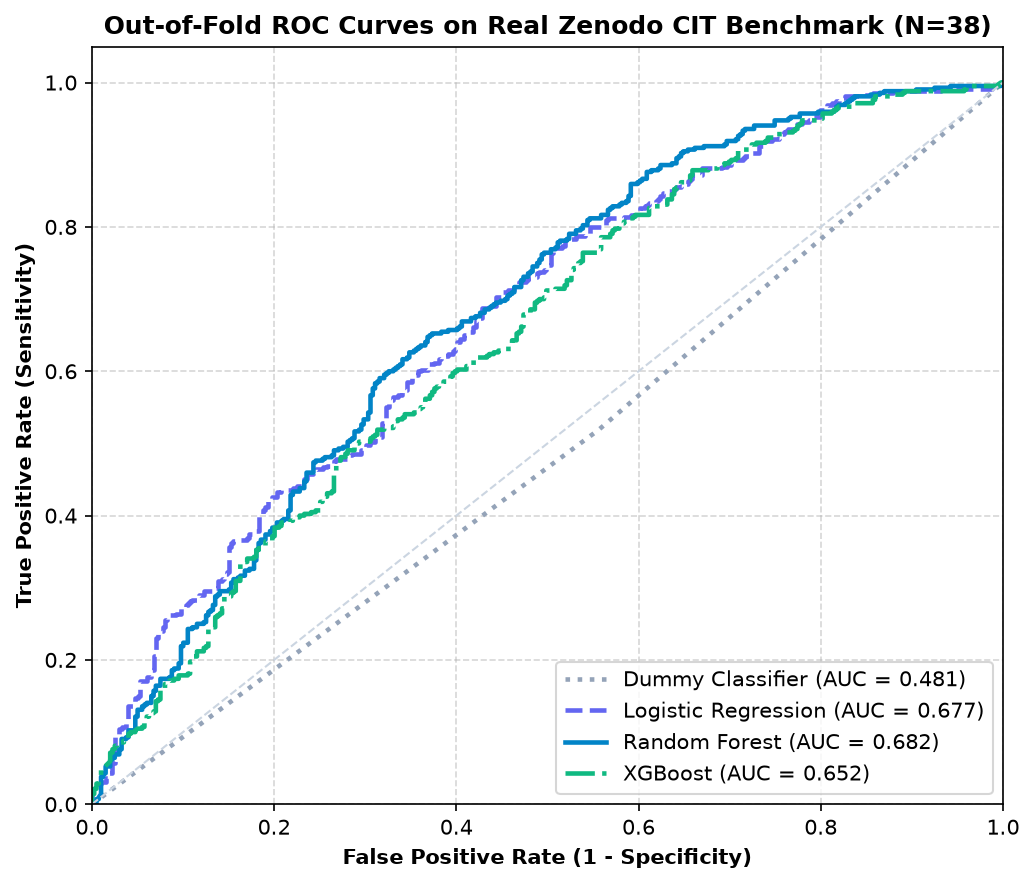

In [3]:
plt.figure(figsize=(7, 6))
colors = {'Dummy Classifier': '#94A3B8', 'Logistic Regression': '#6366F1', 'Random Forest': '#0284C7', 'XGBoost': '#10B981'}
styles = {'Dummy Classifier': ':', 'Logistic Regression': '--', 'Random Forest': '-', 'XGBoost': '-.'}

for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, color=colors[name], linestyle=styles[name], lw=2.2, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], color='#CBD5E1', linestyle='--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity)', fontweight='bold')
plt.title('Out-of-Fold ROC Curves on Real Zenodo CIT Benchmark (N=38)', fontweight='bold')
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()